# 05 - EBAMTN Model B: BiLSTM with Attention and Gating

Implements the Model B component described in the project research notes. The notebook reuses Model A's preprocessing, split-local windows, training, resumption, and original-scale evaluation; it does not run until you execute cells.

## 1. Configuration

This cell is copied from notebook 04; the projection width and attention-head count are added for Model B. Change HORIZONS here for a quick single-horizon run.

In [1]:

from pathlib import Path

LOOKBACK = 48
HORIZONS = [1, 6, 24]
BATCH_SIZE = 256
EPOCHS = 50
LR = 1e-3
HIDDEN = 64
LAYERS = 2
DROPOUT = 0.1
RANDOM_SEED = 42
WEIGHT_DECAY = 1e-4
GRAD_CLIP = 1.0
PATIENCE = 8
FUSED_CHANNELS = 64
FORCE_RETRAIN = False
SCHEDULER_PATIENCE = 3

DATA_PATH = Path(r"C:\Users\jains\Downloads\Air quality dataset\cleaned\air_quality_all_stations_cleaned.csv")
RESULTS_DIR = Path.cwd() / "ebamtn_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print(f"Data: {DATA_PATH}")
print(f"Results: {RESULTS_DIR.resolve()}")

PROJ_DIM = 64
ATTENTION_HEADS = 4


Data: C:\Users\jains\Downloads\Air quality dataset\cleaned\air_quality_all_stations_cleaned.csv
Results: E:\coding\DL2project\ebamtn_results


## 2. Imports, seed, and device

Copied from notebook 04 so Model B uses the same imports, seed setup, and CUDA-if-available device selection.

In [2]:

import copy
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from IPython.display import display, Markdown
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def set_seed(seed=RANDOM_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(8, torch.get_num_threads()))
print(f"PyTorch: {torch.__version__}; device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

from typing import Sequence


PyTorch: 2.15.0+cpu; device: cpu


## 3. Data and chronological splits

Copied from notebook 04. It checks the fixed split boundaries and keeps wind_speed while excluding wind_direction.

In [3]:

if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Cleaned data file not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH, parse_dates=["datetime"])
FEATURES = [
    "PM10", "PM2.5", "temperature", "rain", "pressure", "precipitation",
    "wind_speed", "clouds_ordinal", "hour_sin", "hour_cos",
    "day_of_year_sin", "day_of_year_cos",
]
TARGETS = ["PM10", "PM2.5"]
required_columns = ["datetime", "station", *FEATURES]
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Required columns missing from cleaned data: {missing_columns}")
# Directional wind fields are intentionally excluded; wind_speed remains a feature.
df = df[required_columns].sort_values(["station", "datetime"]).reset_index(drop=True)
if df.duplicated(["station", "datetime"]).any():
    raise ValueError("Duplicate station/timestamp keys must be resolved before window creation.")

all_timestamps = pd.DatetimeIndex(df["datetime"].drop_duplicates().sort_values())
train_cut_idx = int(len(all_timestamps) * 0.70)
validation_cut_idx = int(len(all_timestamps) * 0.85)
if train_cut_idx <= 0 or validation_cut_idx <= train_cut_idx or validation_cut_idx >= len(all_timestamps):
    raise ValueError("Not enough distinct timestamps to create 70/15/15 chronological splits.")
TRAIN_START, TRAIN_END = all_timestamps[0], all_timestamps[train_cut_idx - 1]
VAL_START, VAL_END = all_timestamps[train_cut_idx], all_timestamps[validation_cut_idx - 1]
TEST_START, TEST_END = all_timestamps[validation_cut_idx], all_timestamps[-1]
print(f"Rows: {len(df):,}; stations: {df['station'].nunique()}; features: {len(FEATURES)}")
print(f"Train:      {TRAIN_START} through {TRAIN_END}")
print(f"Validation: {VAL_START} through {VAL_END}")
print(f"Test:       {TEST_START} through {TEST_END}")
print("Every station uses these same chronological cut dates.")
print(f"Wind-direction input columns retained: {[c for c in df.columns if 'wind_direction' in c]}")
expected_dates = [
    "2024-05-02 20:00:00", "2025-06-18 01:00:00",
    "2025-06-18 02:00:00", "2025-09-14 04:00:00",
    "2025-09-14 05:00:00", "2025-12-11 07:00:00",
]
actual_dates = [str(x) for x in [TRAIN_START, TRAIN_END, VAL_START, VAL_END, TEST_START, TEST_END]]
if actual_dates != expected_dates:
    raise ValueError(f"Split dates differ from requested/LSTM dates: {actual_dates}")


Rows: 296,100; stations: 21; features: 12
Train:      2024-05-02 20:00:00 through 2025-06-18 01:00:00
Validation: 2025-06-18 02:00:00 through 2025-09-14 04:00:00
Test:       2025-09-14 05:00:00 through 2025-12-11 07:00:00
Every station uses these same chronological cut dates.
Wind-direction input columns retained: []


## 4. Train-only scaling and split-local windows

Copied from notebook 04 to preserve per-station train-only scalers, NaN handling, targets, and window construction.

In [4]:

class WindowDataset(Dataset):
    '''Lazily slice windows so the full overlapping window tensor stays out of memory.'''
    def __init__(self, station_arrays, records, horizon):
        self.station_arrays = station_arrays
        self.records = records
        self.horizon = horizon

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        station_idx, origin_idx, target_idx = self.records[index]
        arrays = self.station_arrays[station_idx]
        x_start = origin_idx - LOOKBACK + 1
        x = arrays["x"][x_start:origin_idx + 1]
        y_scaled = arrays["y_scaled"][target_idx]
        y_original = arrays["y_original"][target_idx]
        persistence = arrays["persistence"][origin_idx]
        return (
            torch.from_numpy(x), torch.from_numpy(y_scaled),
            torch.tensor(station_idx, dtype=torch.long),
            torch.from_numpy(y_original), torch.from_numpy(persistence),
        )

def build_split_datasets(horizon):
    '''Fit station scalers on train only and create windows contained in each split.'''
    if horizon < 1:
        raise ValueError("HORIZON must be >= 1")
    split_bounds = {
        "train": (TRAIN_START, TRAIN_END),
        "validation": (VAL_START, VAL_END),
        "test": (TEST_START, TEST_END),
    }
    stations = sorted(df["station"].unique())
    station_arrays = {name: [] for name in split_bounds}
    records = {name: [] for name in split_bounds}
    station_scalers = {}
    for station_idx, station in enumerate(stations):
        station_df = df.loc[df["station"].eq(station)].sort_values("datetime").reset_index(drop=True)
        train_mask = station_df["datetime"].between(TRAIN_START, TRAIN_END)
        if train_mask.sum() <= LOOKBACK + horizon:
            raise ValueError(f"Station {station} has too few training rows for the configured window and horizon.")
        train_features = station_df.loc[train_mask, FEATURES].astype(float)
        medians = train_features.median()
        if medians.isna().any():
            bad = medians.index[medians.isna()].tolist()
            raise ValueError(f"Training features entirely missing for station {station}: {bad}")
        feature_scaler = StandardScaler()
        feature_scaler.fit(train_features.fillna(medians).to_numpy(dtype=np.float64))
        target_scalers = {}
        for target in TARGETS:
            valid_train_target = station_df.loc[train_mask, target].dropna().to_numpy(dtype=np.float64).reshape(-1, 1)
            if len(valid_train_target) == 0:
                raise ValueError(f"No valid training targets for {station} / {target}")
            target_scalers[target] = StandardScaler().fit(valid_train_target)
        station_scalers[station] = {
            "features": feature_scaler, "targets": target_scalers, "medians": medians
        }

        # Transform each split independently; no window can cross a split boundary.
        for split_name, (start, end) in split_bounds.items():
            part = station_df.loc[station_df["datetime"].between(start, end)].reset_index(drop=True)
            raw_x = part[FEATURES].astype(float).fillna(medians).to_numpy(dtype=np.float64)
            x_scaled = feature_scaler.transform(raw_x).astype(np.float32)
            y_original = part[TARGETS].to_numpy(dtype=np.float64)
            y_scaled = np.full(y_original.shape, np.nan, dtype=np.float32)
            persistence = part[TARGETS].to_numpy(dtype=np.float64)
            for target_idx, target in enumerate(TARGETS):
                valid = np.isfinite(y_original[:, target_idx])
                target_scaler = target_scalers[target]
                y_scaled[valid, target_idx] = target_scaler.transform(
                    y_original[valid, target_idx].reshape(-1, 1)
                ).ravel().astype(np.float32)
                # The last input observation is the persistence forecast origin.
                input_column_idx = FEATURES.index(target)
            # Preserve the source notebook's persistence arrays at the forecast origin.
            persistence[:, target_idx] = part[target].to_numpy(dtype=np.float64)
            local_arrays = {
                "x": x_scaled, "y_scaled": y_scaled,
                "y_original": y_original.astype(np.float32),
                "persistence": persistence.astype(np.float32),
            }
            station_arrays[split_name].append(local_arrays)
            first_target = LOOKBACK - 1 + horizon
            for target_pos in range(first_target, len(part)):
                origin_pos = target_pos - horizon
                if np.isfinite(y_original[target_pos]).all():
                    records[split_name].append((station_idx, origin_pos, target_pos))

    datasets = {
        name: WindowDataset(station_arrays[name], records[name], horizon)
        for name in split_bounds
    }
    return datasets, station_scalers, stations

print(f"Window builder ready: lookback={LOOKBACK}; horizons={HORIZONS}.")


Window builder ready: lookback=48; horizons=[1, 6, 24].


## 5. DataLoaders and window counts

Copied from notebook 04. It prints train, validation, and test window counts for each horizon.

In [5]:

def make_dataloaders(
    datasets: dict[str, WindowDataset],
) -> tuple[dict[str, DataLoader], torch.Generator]:
    '''Create the shared train, validation, and test loaders.'''
    counts = {name: len(dataset) for name, dataset in datasets.items()}
    print(
        "Windows train/validation/test = "
        f"{counts['train']:,}/{counts['validation']:,}/{counts['test']:,}"
    )
    train_generator = torch.Generator().manual_seed(RANDOM_SEED)
    loaders = {
        "train": DataLoader(
            datasets["train"], batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
            pin_memory=DEVICE.type == "cuda",
            generator=train_generator,
        ),
        "validation": DataLoader(
            datasets["validation"], batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
            pin_memory=DEVICE.type == "cuda",
        ),
        "test": DataLoader(
            datasets["test"], batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
            pin_memory=DEVICE.type == "cuda",
        ),
    }
    return loaders, train_generator


## 6. Model B: BiLSTM with multi-head self-attention and gating

The model accepts (batch, time, features) directly. The bidirectional encoder only sees the supplied historical window.

In [6]:
class BiLSTMAttentionGate(nn.Module):
    """Bidirectional history encoder fused with self-attention through a gate."""

    def __init__(
        self,
        input_size: int,
        hidden_size: int = HIDDEN,
        layers: int = LAYERS,
        projection_dim: int = PROJ_DIM,
        num_heads: int = ATTENTION_HEADS,
        dropout: float = DROPOUT,
    ) -> None:
        super().__init__()
        if hidden_size * 2 % num_heads != 0:
            raise ValueError("The bidirectional embedding size must divide evenly across heads.")
        embedding_dim = hidden_size * 2
        self.bilstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if layers > 1 else 0.0,
        )
        self.attention = nn.MultiheadAttention(
            embed_dim=embedding_dim,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True,
        )
        self.gate_projection = nn.Linear(embedding_dim * 2, embedding_dim)
        self.output_projection = nn.Sequential(
            nn.Linear(embedding_dim, projection_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

    def forward(
        self,
        x: torch.Tensor,
        return_attention: bool = False,
        return_gate: bool = False,
        return_gate_values: bool = False,
    ) -> torch.Tensor | tuple[torch.Tensor, ...]:
        """Encode (batch, time, features); optionally return diagnostics."""
        if x.ndim != 3:
            raise ValueError("Expected input shape (batch, time, features).")

        # Both directions traverse only the supplied past input window.
        # No observations after the forecast origin are included in x.
        hidden, _ = self.bilstm(x)
        attended, attention_weights = self.attention(
            hidden,
            hidden,
            hidden,
            need_weights=return_attention,
            average_attn_weights=True,
        )
        gate = torch.sigmoid(
            self.gate_projection(torch.cat((hidden, attended), dim=-1))
        )
        fused = gate * hidden + (1.0 - gate) * attended
        projected = self.output_projection(fused)

        extras: list[torch.Tensor] = []
        if return_attention:
            if attention_weights is None:
                raise RuntimeError("Attention weights were requested but not returned.")
            extras.append(attention_weights)
        if return_gate:
            extras.append(gate.mean())
        if return_gate_values:
            extras.append(gate)
        return (projected, *extras) if extras else projected


class BiLSTMAttentionGateNet(nn.Module):
    """Jointly forecast PM10 and PM2.5 from a historical feature window."""

    def __init__(
        self,
        input_size: int,
        projection_dim: int = PROJ_DIM,
        dropout: float = DROPOUT,
    ) -> None:
        super().__init__()
        self.encoder = BiLSTMAttentionGate(
            input_size=input_size,
            projection_dim=projection_dim,
            dropout=dropout,
        )
        self.head = nn.Sequential(
            nn.Linear(projection_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 2),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Return [PM10, PM2.5] at t+HORIZON without changing input layout."""
        encoded = self.encoder(x)
        return self.head(encoded[:, -1, :])


def count_trainable_parameters(model: nn.Module) -> int:
    """Count parameters updated by the optimizer."""
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


## 7. Model shape and parameter sanity check

A random input checks the requested joint-output shape and reports the trainable parameter count when you run this cell.

In [7]:
sanity_model_b = BiLSTMAttentionGateNet(input_size=len(FEATURES)).to(DEVICE).eval()
random_input = torch.randn(8, LOOKBACK, len(FEATURES), device=DEVICE)
with torch.no_grad():
    random_output = sanity_model_b(random_input)
assert random_output.shape == (8, 2), f"Unexpected output shape: {tuple(random_output.shape)}"
print(f"Sanity check passed: output shape={tuple(random_output.shape)}")
print(f"Model B trainable parameters: {count_trainable_parameters(sanity_model_b):,}")


Sanity check passed: output shape=(8, 2)
Model B trainable parameters: 250,754


## 8. Attention and gate checks

Checks that averaged attention weights sum to one over key time and that every sigmoid gate value is strictly between zero and one.

In [8]:
diagnostic_block = BiLSTMAttentionGate(input_size=len(FEATURES)).to(DEVICE).eval()
diagnostic_input = torch.randn(8, LOOKBACK, len(FEATURES), device=DEVICE)
with torch.no_grad():
    projected, attention_weights, mean_gate, gate_values = diagnostic_block(
        diagnostic_input,
        return_attention=True,
        return_gate=True,
        return_gate_values=True,
    )

expected_attention_shape = (8, LOOKBACK, LOOKBACK)
assert attention_weights.shape == expected_attention_shape, (
    f"Unexpected attention shape: {tuple(attention_weights.shape)}"
)
torch.testing.assert_close(
    attention_weights.sum(dim=-1),
    torch.ones(8, LOOKBACK, device=DEVICE),
    rtol=1e-5,
    atol=1e-6,
)
assert torch.all(gate_values > 0).item() and torch.all(gate_values < 1).item(), (
    "Sigmoid gate values must lie strictly between zero and one."
)
assert 0.0 < mean_gate.item() < 1.0
print("Attention weights sum to 1 over the key-time axis; gate values are in (0, 1).")


Attention weights sum to 1 over the key-time axis; gate values are in (0, 1).


## 9. Parameter-count reference

Uses available imported classes or saved parameter-count CSVs for the existing models, then compares them with Model B.

In [9]:
parameter_counts = {
    "Model B": count_trainable_parameters(
        BiLSTMAttentionGateNet(input_size=len(FEATURES))
    )
}
recorded_counts = {}
tcn_counts_path = Path.cwd() / "tcn_cnn_results" / "training_time_parameter_counts.csv"
if tcn_counts_path.is_file():
    recorded = pd.read_csv(tcn_counts_path)
    name_map = {
        "LSTM (reference)": "LSTM",
        "LSTM": "LSTM",
        "TCN": "TCN",
        "1D-CNN": "1D-CNN",
    }
    for _, row in recorded.iterrows():
        label = name_map.get(str(row.get("model", "")))
        value = pd.to_numeric(row.get("trainable_parameters"), errors="coerce")
        if label and pd.notna(value):
            recorded_counts[label] = int(value)
else:
    print(f"Parameter-count reference file not found: {tcn_counts_path}")

model_a_summary_path = RESULTS_DIR / "model_a_training_summary.csv"
if model_a_summary_path.is_file():
    model_a_summary = pd.read_csv(model_a_summary_path)
    model_a_values = pd.to_numeric(
        model_a_summary.get("trainable_parameters"), errors="coerce"
    ).dropna()
    if not model_a_values.empty:
        recorded_counts["Model A"] = int(model_a_values.iloc[0])
else:
    print(f"Model A parameter-count file not found: {model_a_summary_path}")

parameter_rows = []
for label in ["LSTM", "TCN", "1D-CNN", "Model A"]:
    class_names = {
        "LSTM": "PooledLSTM",
        "TCN": "PooledTCN",
        "1D-CNN": "PooledCNN1D",
        "Model A": "MultiScaleAttentionTCN",
    }
    model_class = globals().get(class_names[label])
    if isinstance(model_class, type) and issubclass(model_class, nn.Module):
        count = count_trainable_parameters(model_class(len(FEATURES)))
        source = "importable class"
    elif label in recorded_counts:
        count = recorded_counts[label]
        source = "saved CSV"
    else:
        print(f"Parameter count unavailable for {label}.")
        continue
    parameter_rows.append({"model": label, "trainable_parameters": count, "source": source})

MODEL_B_PARAMETER_COUNT = parameter_counts["Model B"]
parameter_rows.append({
    "model": "Model B",
    "trainable_parameters": MODEL_B_PARAMETER_COUNT,
    "source": "current architecture",
})
parameter_count_table = pd.DataFrame(parameter_rows)
display(parameter_count_table)


,model,trainable_parameters,source
0,LSTM,53378,saved CSV
1,TCN,115778,saved CSV
2,1D-CNN,20194,saved CSV
3,Model A,118661,saved CSV
4,Model B,250754,current architecture


## 10. Reusable training and evaluation functions

Copied from notebook 04. fit_model passes each (batch, time, features) batch directly to model(x); there is no Model A Conv1d permutation in the shared training or evaluation code.

In [10]:

def regression_metrics(actual, predicted):
    '''Compute finite-value MAE, RMSE, R2, and sample count.'''
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    valid = np.isfinite(actual) & np.isfinite(predicted)
    actual, predicted = actual[valid], predicted[valid]
    if not len(actual):
        return {"MAE": np.nan, "RMSE": np.nan, "R2": np.nan, "n": 0}
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted) if len(actual) >= 2 else np.nan,
        "n": len(actual),
    }

def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: nn.Module,
) -> float:
    '''Run one training epoch and clip the global gradient norm.'''
    model.train()
    loss_sum, sample_count = 0.0, 0
    for x, y, _, _, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(x), y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP)
        optimizer.step()
        loss_sum += loss.item() * len(x)
        sample_count += len(x)
    if sample_count == 0:
        raise ValueError("Training DataLoader produced no samples.")
    return loss_sum / sample_count

def validate_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
) -> float:
    '''Compute sample-weighted validation MSE without updating model state.'''
    model.eval()
    loss_sum, sample_count = 0.0, 0
    with torch.no_grad():
        for x, y, _, _, _ in loader:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            loss_sum += criterion(model(x), y).item() * len(x)
            sample_count += len(x)
    if sample_count == 0:
        raise ValueError("Validation DataLoader produced no samples.")
    return loss_sum / sample_count

def fit_model(
    model: nn.Module,
    train_loader: DataLoader,
    validation_loader: DataLoader,
    train_generator: torch.Generator,
    resume_path: Path,
) -> dict[str, object]:
    '''Train or resume a model, saving its complete state after each epoch.'''
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY
    )
    criterion = nn.MSELoss()
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=SCHEDULER_PATIENCE
    )
    history = {"train_loss": [], "validation_loss": []}
    best_state = None
    best_validation_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0
    start_epoch = 1
    elapsed_before_resume = 0.0

    if resume_path.is_file():
        checkpoint = torch.load(resume_path, map_location="cpu", weights_only=True)
        model.load_state_dict(checkpoint["model_state"])
        optimizer.load_state_dict(checkpoint["optimizer_state"])
        scheduler.load_state_dict(checkpoint["scheduler_state"])
        train_generator.set_state(checkpoint["train_generator_state"])
        torch.set_rng_state(checkpoint["torch_rng_state"])
        cuda_rng_states = checkpoint["cuda_rng_states"]
        if torch.cuda.is_available() and cuda_rng_states:
            torch.cuda.set_rng_state_all(cuda_rng_states)
        history = checkpoint["history"]
        best_state = checkpoint["best_state"]
        best_validation_loss = checkpoint["best_validation_loss"]
        best_epoch = checkpoint["best_epoch"]
        epochs_without_improvement = checkpoint["epochs_without_improvement"]
        start_epoch = checkpoint["epoch"] + 1
        elapsed_before_resume = checkpoint["elapsed_seconds"]
        print(f"Resuming from completed epoch {start_epoch - 1} ({resume_path}).")

    started = time.perf_counter()
    for epoch in range(start_epoch, EPOCHS + 1):
        if epochs_without_improvement >= PATIENCE:
            print("Early-stopping patience was already exhausted in the saved checkpoint.")
            break
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        validation_loss = validate_one_epoch(model, validation_loader, criterion)
        scheduler.step(validation_loss)
        history["train_loss"].append(train_loss)
        history["validation_loss"].append(validation_loss)
        if validation_loss < best_validation_loss:
            best_validation_loss = validation_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        print(
            f"epoch {epoch:02d}/{EPOCHS} | train={train_loss:.5f} | "
            f"val={validation_loss:.5f} | "
            f"lr={optimizer.param_groups[0]['lr']:.2e}"
        )

        checkpoint = {
            "epoch": epoch,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(),
            "best_state": best_state,
            "best_validation_loss": best_validation_loss,
            "best_epoch": best_epoch,
            "epochs_without_improvement": epochs_without_improvement,
            "history": history,
            "elapsed_seconds": elapsed_before_resume + time.perf_counter() - started,
            "train_generator_state": train_generator.get_state(),
            "torch_rng_state": torch.get_rng_state(),
            "cuda_rng_states": torch.cuda.get_rng_state_all()
            if torch.cuda.is_available() else [],
        }
        temporary_path = resume_path.with_suffix(resume_path.suffix + ".tmp")
        torch.save(checkpoint, temporary_path)
        temporary_path.replace(resume_path)

        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping after {PATIENCE} epochs without improvement.")
            break

    if best_state is None:
        raise RuntimeError("Training ended without a finite validation checkpoint.")
    model.load_state_dict(best_state)
    return {
        "history": history,
        "best_state": best_state,
        "best_epoch": best_epoch,
        "best_validation_loss": best_validation_loss,
        "epochs_run": len(history["train_loss"]),
        "training_seconds": elapsed_before_resume + time.perf_counter() - started,
    }

def evaluate_model(
    model: nn.Module,
    horizon: int,
    test_loader: DataLoader,
    station_scalers: dict,
    stations: list[str],
) -> tuple[pd.DataFrame, pd.DataFrame]:
    '''Return original-scale pooled/per-station metrics and test predictions.'''
    model.eval()
    prediction_scaled, actual_original = [], []
    persistence_original, station_indices = [], []
    with torch.no_grad():
        for x, _, station_id, actual, persistence in test_loader:
            prediction_scaled.append(model(x.to(DEVICE, non_blocking=True)).cpu().numpy())
            actual_original.append(actual.numpy())
            persistence_original.append(persistence.numpy())
            station_indices.append(station_id.numpy())
    prediction_scaled = np.concatenate(prediction_scaled)
    actual_original = np.concatenate(actual_original)
    persistence_original = np.concatenate(persistence_original)
    station_indices = np.concatenate(station_indices)
    station_names = np.asarray(stations, dtype=object)[station_indices]

    prediction_original = np.empty_like(prediction_scaled, dtype=np.float64)
    for station_idx, station in enumerate(stations):
        rows = station_indices == station_idx
        for target_idx, target in enumerate(TARGETS):
            scaler = station_scalers[station]["targets"][target]
            prediction_original[rows, target_idx] = scaler.inverse_transform(
                prediction_scaled[rows, target_idx].reshape(-1, 1)
            ).ravel()

    test_dates = []
    # Match notebook 03's station-major, chronological prediction ordering.
    for station in stations:
        part = df.loc[
            df["station"].eq(station)
            & df["datetime"].between(TEST_START, TEST_END)
        ].reset_index(drop=True)
        first_target = LOOKBACK - 1 + horizon
        valid_positions = [
            pos for pos in range(first_target, len(part))
            if np.isfinite(part.loc[pos, TARGETS].to_numpy(dtype=float)).all()
        ]
        test_dates.extend(part.loc[valid_positions, "datetime"].tolist())
    predictions = pd.DataFrame({
        "station": station_names,
        "datetime": test_dates,
        "PM10_actual": actual_original[:, 0],
        "PM10_predicted": prediction_original[:, 0],
        "PM2.5_actual": actual_original[:, 1],
        "PM2.5_predicted": prediction_original[:, 1],
        "PM10_persistence": persistence_original[:, 0],
        "PM2.5_persistence": persistence_original[:, 1],
    })

    metric_rows = []
    for target_idx, target in enumerate(TARGETS):
        groups = [("overall", np.ones(len(station_names), dtype=bool))] + [
            (station, station_names == station) for station in stations
        ]
        for group, mask in groups:
            values = regression_metrics(
                actual_original[mask, target_idx],
                prediction_original[mask, target_idx],
            )
            metric_rows.append({
                "horizon": horizon,
                "target": target,
                "station": group,
                "method": "Model B",
                **values,
            })
    return pd.DataFrame(metric_rows), predictions


## 11. Train and evaluate Model B by horizon

Saves Model B-only artifacts and a full atomic resume checkpoint after each completed epoch. A mid-epoch interruption repeats that epoch; FORCE_RETRAIN controls skipping completed horizons.

Windows train/validation/test = 203,749/42,142/43,041
epoch 01/50 | train=0.16852 | val=0.06342 | lr=1.00e-03
epoch 02/50 | train=0.11802 | val=0.06230 | lr=1.00e-03
epoch 03/50 | train=0.11416 | val=0.05885 | lr=1.00e-03
epoch 04/50 | train=0.11310 | val=0.06064 | lr=1.00e-03
epoch 05/50 | train=0.11205 | val=0.05777 | lr=1.00e-03
epoch 06/50 | train=0.11102 | val=0.05749 | lr=1.00e-03
epoch 07/50 | train=0.11004 | val=0.05686 | lr=1.00e-03
epoch 08/50 | train=0.10902 | val=0.05700 | lr=1.00e-03
epoch 09/50 | train=0.10887 | val=0.05617 | lr=1.00e-03
epoch 10/50 | train=0.10817 | val=0.05769 | lr=1.00e-03
epoch 11/50 | train=0.10755 | val=0.05618 | lr=1.00e-03
epoch 12/50 | train=0.10746 | val=0.05550 | lr=1.00e-03
epoch 13/50 | train=0.10653 | val=0.05617 | lr=1.00e-03
epoch 14/50 | train=0.10614 | val=0.05570 | lr=1.00e-03
epoch 15/50 | train=0.10661 | val=0.05580 | lr=1.00e-03
epoch 16/50 | train=0.10589 | val=0.05676 | lr=5.00e-04
epoch 17/50 | train=0.10337 | val=0.05550 | lr=5.0

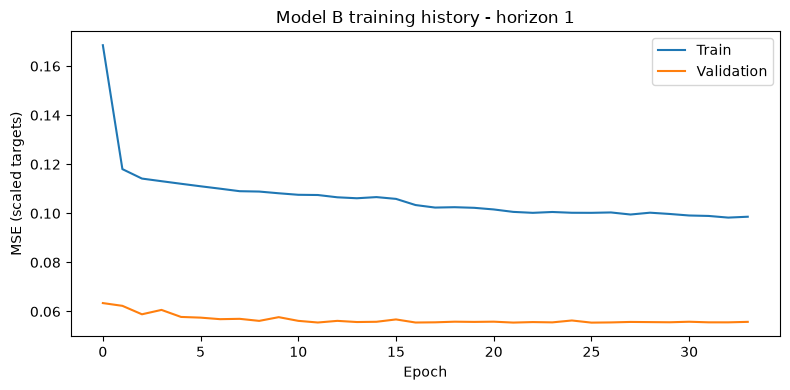

H=1: best epoch 26; training time 10077.2s


,horizon,target,station,method,MAE,RMSE,R2,n
0,1,PM10,overall,Model B,2.742056,4.846928,0.839533,43041
1,1,PM10,E403,Model B,2.721474,4.646284,0.857520,2067
2,1,PM10,E404,Model B,2.673447,4.637409,0.865457,2067
3,1,PM10,E405,Model B,2.389143,3.656101,0.900542,2067
4,1,PM10,E407,Model B,2.406913,4.445601,0.734470,2061
5,1,PM10,E408,Model B,1.906636,2.807758,0.873643,2067


Windows train/validation/test = 203,644/42,037/42,936
epoch 01/50 | train=0.37203 | val=0.10574 | lr=1.00e-03
epoch 02/50 | train=0.29510 | val=0.09610 | lr=1.00e-03
epoch 03/50 | train=0.27058 | val=0.09640 | lr=1.00e-03
epoch 04/50 | train=0.25045 | val=0.09530 | lr=1.00e-03
epoch 05/50 | train=0.23748 | val=0.10105 | lr=1.00e-03
epoch 06/50 | train=0.22428 | val=0.09488 | lr=1.00e-03
epoch 07/50 | train=0.21251 | val=0.09493 | lr=1.00e-03
epoch 08/50 | train=0.20260 | val=0.09609 | lr=1.00e-03
epoch 09/50 | train=0.19327 | val=0.09609 | lr=1.00e-03
epoch 10/50 | train=0.18661 | val=0.09901 | lr=5.00e-04
epoch 11/50 | train=0.16625 | val=0.09826 | lr=5.00e-04
epoch 12/50 | train=0.15921 | val=0.10038 | lr=5.00e-04
epoch 13/50 | train=0.15575 | val=0.10043 | lr=5.00e-04
epoch 14/50 | train=0.15075 | val=0.10129 | lr=2.50e-04
Early stopping after 8 epochs without improvement.


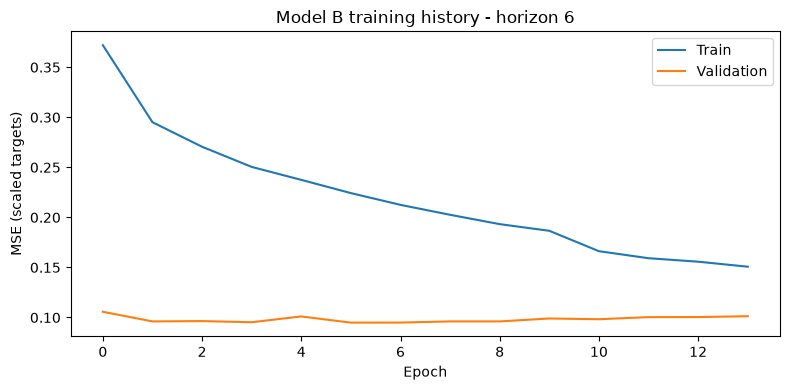

H=6: best epoch 6; training time 4107.1s


,horizon,target,station,method,MAE,RMSE,R2,n
0,6,PM10,overall,Model B,6.126139,8.895188,0.460361,42936
1,6,PM10,E403,Model B,6.008045,8.510094,0.522830,2062
2,6,PM10,E404,Model B,6.492105,9.085121,0.484687,2062
3,6,PM10,E405,Model B,5.482562,7.483713,0.584064,2062
4,6,PM10,E407,Model B,5.527397,7.824688,0.179099,2056
5,6,PM10,E408,Model B,4.521817,6.139281,0.397193,2062


Windows train/validation/test = 203,266/41,659/42,558
epoch 01/50 | train=0.46776 | val=0.18159 | lr=1.00e-03
epoch 02/50 | train=0.35382 | val=0.16052 | lr=1.00e-03
epoch 03/50 | train=0.30191 | val=0.16598 | lr=1.00e-03
epoch 04/50 | train=0.27324 | val=0.17788 | lr=1.00e-03
epoch 05/50 | train=0.25152 | val=0.15986 | lr=1.00e-03
epoch 06/50 | train=0.23447 | val=0.15276 | lr=1.00e-03
epoch 07/50 | train=0.22118 | val=0.19352 | lr=1.00e-03
epoch 08/50 | train=0.21074 | val=0.15608 | lr=1.00e-03
epoch 09/50 | train=0.20135 | val=0.17273 | lr=1.00e-03
epoch 10/50 | train=0.19313 | val=0.17119 | lr=5.00e-04
epoch 11/50 | train=0.16836 | val=0.20216 | lr=5.00e-04
epoch 12/50 | train=0.16219 | val=0.20439 | lr=5.00e-04
epoch 13/50 | train=0.15880 | val=0.22768 | lr=5.00e-04
epoch 14/50 | train=0.15501 | val=0.19225 | lr=2.50e-04
Early stopping after 8 epochs without improvement.


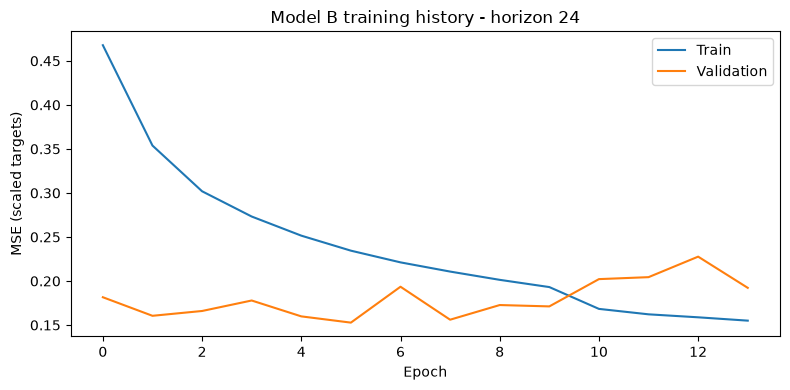

H=24: best epoch 6; training time 4145.7s


,horizon,target,station,method,MAE,RMSE,R2,n
0,24,PM10,overall,Model B,7.756107,10.734421,0.216594,42558
1,24,PM10,E403,Model B,7.941660,10.352554,0.280733,2044
2,24,PM10,E404,Model B,8.489733,11.344923,0.198388,2044
3,24,PM10,E405,Model B,7.664900,9.961246,0.263346,2044
4,24,PM10,E407,Model B,6.581220,8.732042,-0.019299,2038
5,24,PM10,E408,Model B,5.811802,7.512837,0.101179,2044


,model,horizon,best_epoch,epochs_run,best_validation_loss,training_time_seconds,trainable_parameters
0,Model B - BiLSTM with attention and gating,1,26,34,0.055456,10077.218429,250754
1,Model B - BiLSTM with attention and gating,6,6,14,0.094877,4107.061321,250754
2,Model B - BiLSTM with attention and gating,24,6,14,0.152764,4145.678934,250754


In [11]:
def run_model_b_horizon(horizon: int) -> dict[str, object] | None:
    """Train/evaluate one horizon, resuming from the last completed epoch."""
    weights_path = RESULTS_DIR / f"model_b_horizon_{horizon}_best.pt"
    resume_path = RESULTS_DIR / f"model_b_horizon_{horizon}_resume.pt"
    metrics_path = RESULTS_DIR / f"model_b_horizon_{horizon}_metrics.csv"
    training_path = RESULTS_DIR / f"model_b_horizon_{horizon}_training.csv"
    predictions_path = RESULTS_DIR / f"model_b_horizon_{horizon}_test_predictions.csv"
    loss_path = RESULTS_DIR / f"model_b_horizon_{horizon}_loss.png"

    if weights_path.is_file() and not FORCE_RETRAIN:
        print(
            f"Skipping H={horizon}: completed Model B weights exist at {weights_path}. "
            "Set FORCE_RETRAIN=True to train again."
        )
        if training_path.is_file():
            return pd.read_csv(training_path).iloc[0].to_dict()
        return None

    set_seed(RANDOM_SEED)
    datasets, station_scalers, stations = build_split_datasets(horizon)
    loaders, train_generator = make_dataloaders(datasets)
    model = BiLSTMAttentionGateNet(input_size=len(FEATURES)).to(DEVICE)
    fit_result = fit_model(
        model=model,
        train_loader=loaders["train"],
        validation_loader=loaders["validation"],
        train_generator=train_generator,
        resume_path=resume_path,
    )
    training_seconds = fit_result["training_seconds"]

    metrics, predictions = evaluate_model(
        model=model,
        horizon=horizon,
        test_loader=loaders["test"],
        station_scalers=station_scalers,
        stations=stations,
    )
    metrics.to_csv(metrics_path, index=False)
    predictions.to_csv(predictions_path, index=False)

    history = fit_result["history"]
    figure, axis = plt.subplots(figsize=(8, 4))
    axis.plot(history["train_loss"], label="Train")
    axis.plot(history["validation_loss"], label="Validation")
    axis.set(
        title=f"Model B training history - horizon {horizon}",
        xlabel="Epoch",
        ylabel="MSE (scaled targets)",
    )
    axis.legend()
    figure.tight_layout()
    figure.savefig(loss_path, dpi=150)
    plt.show()
    plt.close(figure)

    summary = {
        "model": "Model B - BiLSTM with attention and gating",
        "horizon": horizon,
        "best_epoch": fit_result["best_epoch"],
        "epochs_run": fit_result["epochs_run"],
        "best_validation_loss": fit_result["best_validation_loss"],
        "training_time_seconds": training_seconds,
        "trainable_parameters": count_trainable_parameters(model),
    }
    pd.DataFrame([summary]).to_csv(training_path, index=False)

    # The best-weights file is atomically replaced and marks completion.
    temporary_weights_path = weights_path.with_suffix(weights_path.suffix + ".tmp")
    torch.save(fit_result["best_state"], temporary_weights_path)
    temporary_weights_path.replace(weights_path)
    if resume_path.is_file():
        resume_path.unlink()

    print(
        f"H={horizon}: best epoch {summary['best_epoch']}; "
        f"training time {training_seconds:.1f}s"
    )
    display(metrics.head(6))
    return summary


RESULTS_DIR.mkdir(parents=True, exist_ok=True)
run_summaries = []
for horizon in HORIZONS:
    horizon_summary = run_model_b_horizon(horizon)
    if horizon_summary is not None:
        run_summaries.append(horizon_summary)

summary_path = RESULTS_DIR / "model_b_training_summary.csv"
if summary_path.is_file():
    prior_summaries = pd.read_csv(summary_path)
    run_summaries = prior_summaries.to_dict(orient="records") + run_summaries
if run_summaries:
    summary_frame = pd.DataFrame(run_summaries).drop_duplicates(
        subset=["horizon"], keep="last"
    ).sort_values("horizon")
    summary_frame.to_csv(summary_path, index=False)
    display(summary_frame)


## 12. Compare saved pooled metrics

Reads existing metrics only, skips missing model files with a message, highlights best values, and saves the requested comparison table and RMSE improvements. It does not retrain models.

In [13]:
PROJECT_DIR = Path.cwd()
MODEL_ORDER = ["Persistence", "LSTM", "TCN", "1D-CNN", "Model A", "Model B"]
METRICS = ["MAE", "RMSE", "R2"]
pooled_metric_frames = []


def load_pooled_metric_file(
    path: Path,
    model_name: str,
    method_name: str,
) -> None:
    """Append pooled rows from one saved metrics CSV, or report it missing."""
    if not path.is_file():
        print(f"Skipping {model_name}: metrics file not found: {path}")
        return
    frame = pd.read_csv(path)
    if "station" not in frame.columns:
        raise ValueError(f"Metrics file has no station column: {path}")
    pooled = frame.loc[frame["station"].astype(str).str.lower().eq("overall")].copy()
    if "method" in pooled.columns:
        pooled = pooled.loc[pooled["method"].eq(method_name)]
    if pooled.empty:
        print(f"Skipping {model_name}: no pooled {method_name} rows in {path}")
        return
    pooled["model"] = model_name
    pooled_metric_frames.append(pooled[["horizon", "target", "model", *METRICS]])


lstm_metrics_path = PROJECT_DIR / "lstm_results" / "lstm_all_horizons_metrics.csv"
load_pooled_metric_file(lstm_metrics_path, "Persistence", "Persistence")
load_pooled_metric_file(lstm_metrics_path, "LSTM", "LSTM")
load_pooled_metric_file(
    PROJECT_DIR / "tcn_cnn_results" / "tcn_all_horizons_metrics.csv",
    "TCN",
    "TCN",
)
load_pooled_metric_file(
    PROJECT_DIR / "tcn_cnn_results" / "1d_cnn_all_horizons_metrics.csv",
    "1D-CNN",
    "1D-CNN",
)


def load_horizon_metric_files(prefix: str, model_name: str) -> None:
    """Append pooled per-horizon metrics for a paper component, if present."""
    files = sorted(RESULTS_DIR.glob(f"{prefix}_horizon_*_metrics.csv"))
    if not files:
        print(f"Skipping {model_name}: no {prefix}_horizon_*_metrics.csv files found.")
        return
    for path in files:
        load_pooled_metric_file(path, model_name, model_name)


load_horizon_metric_files("model_a", "Model A")
load_horizon_metric_files("model_b", "Model B")

if not pooled_metric_frames:
    raise ValueError("No pooled metrics were found; comparison cannot be built.")
comparison_long = pd.concat(pooled_metric_frames, ignore_index=True)
comparison_long["horizon"] = pd.to_numeric(comparison_long["horizon"], errors="raise").astype(int)
comparison_long = comparison_long.drop_duplicates(
    subset=["target", "horizon", "model"], keep="last"
)
available_models = [name for name in MODEL_ORDER if name in set(comparison_long["model"])]

metric_pivot = comparison_long.pivot_table(
    index=["target", "horizon"],
    columns="model",
    values=METRICS,
    aggfunc="first",
)
comparison_wide = pd.DataFrame(index=metric_pivot.index)
for model_name in available_models:
    for metric_name in METRICS:
        if (metric_name, model_name) in metric_pivot.columns:
            comparison_wide[f"{model_name}_{metric_name}"] = metric_pivot[
                (metric_name, model_name)
            ]
        else:
            comparison_wide[f"{model_name}_{metric_name}"] = np.nan

for metric_name in METRICS:
    model_columns = [f"{model_name}_{metric_name}" for model_name in available_models]
    best_names = []
    for _, row in comparison_wide.iterrows():
        candidates = {
            model_name: row[f"{model_name}_{metric_name}"]
            for model_name in available_models
            if pd.notna(row[f"{model_name}_{metric_name}"])
        }
        if not candidates:
            best_names.append("NOT AVAILABLE / NOT RUN")
        elif metric_name in ("MAE", "RMSE"):
            best_names.append(min(candidates, key=candidates.get))
        else:
            best_names.append(max(candidates, key=candidates.get))
    comparison_wide[f"best_{metric_name}_model"] = best_names

comparison_table = comparison_wide.reset_index()
comparison_table_path = RESULTS_DIR / "model_a_b_comparison_table.csv"
comparison_table.to_csv(comparison_table_path, index=False)


def highlight_best_comparison_values(row: pd.Series) -> list[str]:
    """Highlight each row's minimum errors and maximum R2 in the display."""
    styles = [""] * len(row)
    for metric_name in METRICS:
        winner = row.get(f"best_{metric_name}_model")
        column_name = f"{winner}_{metric_name}"
        if winner in available_models and column_name in row.index:
            styles[row.index.get_loc(column_name)] = (
                "background-color: #b7e4c7; font-weight: bold"
            )
    return styles


display(comparison_table.style.apply(highlight_best_comparison_values, axis=1))
print(f"Saved comparison table: {comparison_table_path}")

improvement_rows = []
if "Persistence_RMSE" not in comparison_table.columns:
    print("Persistence pooled RMSE is unavailable; improvement percentages cannot be computed.")
else:
    for _, row in comparison_table.iterrows():
        baseline = row["Persistence_RMSE"]
        for model_name in available_models:
            model_column = f"{model_name}_RMSE"
            model_rmse = row.get(model_column, np.nan)
            if pd.isna(baseline) or pd.isna(model_rmse) or baseline == 0:
                improvement = np.nan
            else:
                improvement = (baseline - model_rmse) / baseline * 100.0
            improvement_rows.append({
                "target": row["target"],
                "horizon": int(row["horizon"]),
                "model": model_name,
                "rmse_improvement_percent": improvement,
            })
improvement_table = pd.DataFrame(improvement_rows)
improvement_path = RESULTS_DIR / "model_b_rmse_improvement_vs_persistence.csv"
improvement_table.to_csv(improvement_path, index=False)
display(improvement_table)


,target,horizon,Persistence_MAE,Persistence_RMSE,Persistence_R2,LSTM_MAE,LSTM_RMSE,LSTM_R2,TCN_MAE,TCN_RMSE,TCN_R2,1D-CNN_MAE,1D-CNN_RMSE,1D-CNN_R2,Model A_MAE,Model A_RMSE,Model A_R2,Model B_MAE,Model B_RMSE,Model B_R2,best_MAE_model,best_RMSE_model,best_R2_model
0,PM10,1,2.883509,5.397647,0.800890,2.757839,4.891815,0.836547,2.762742,4.886255,0.836918,3.448053,5.238078,0.812588,2.731283,4.832126,0.840511,2.742056,4.846928,0.839533,Model A,Model A,Model A
1,PM10,6,7.313310,11.435296,0.104835,6.153512,9.003243,0.447170,5.554920,8.123951,0.549880,7.573089,10.160912,0.295860,5.570065,8.155341,0.546395,6.126139,8.895188,0.460361,TCN,TCN,TCN
2,PM10,24,7.257330,10.865409,0.190566,7.675617,10.510997,0.248866,7.591874,10.940719,0.186193,10.319487,13.224941,-0.189097,7.584839,10.291804,0.279867,7.756107,10.734421,0.216594,Persistence,Model A,Model A
3,PM2.5,1,2.056374,4.037258,0.857229,1.974880,3.676273,0.881713,2.001635,3.699061,0.880242,2.407861,3.881301,0.868151,1.978183,3.644742,0.883733,1.964504,3.659467,0.882792,Model B,Model A,Model A
4,PM2.5,6,5.626528,9.368943,0.229830,4.579632,7.179857,0.549589,4.202046,6.438681,0.637781,5.757547,8.091354,0.427968,4.150452,6.436871,0.637984,4.496896,6.853268,0.589632,Model A,Model A,Model A
5,PM2.5,24,5.544538,8.705820,0.333732,5.727616,8.440200,0.379962,5.937502,9.065317,0.284715,8.139442,10.911222,-0.036238,5.940471,8.497790,0.371471,6.059412,8.813710,0.323870,Persistence,LSTM,LSTM


Saved comparison table: e:\coding\DL2project\ebamtn_results\model_a_b_comparison_table.csv


,target,horizon,model,rmse_improvement_percent
0,PM10,1,Persistence,0.000000
1,PM10,1,LSTM,9.371343
2,PM10,1,TCN,9.474345
3,PM10,1,1D-CNN,2.956258
4,PM10,1,Model A,10.477176
5,PM10,1,Model B,10.202946
6,PM10,6,Persistence,0.000000
7,PM10,6,LSTM,21.267952
8,PM10,6,TCN,28.957228
9,PM10,6,1D-CNN,11.144308


## 13. Comparison charts

Plots saved pooled RMSE and R2 by horizon for all models with available metrics.

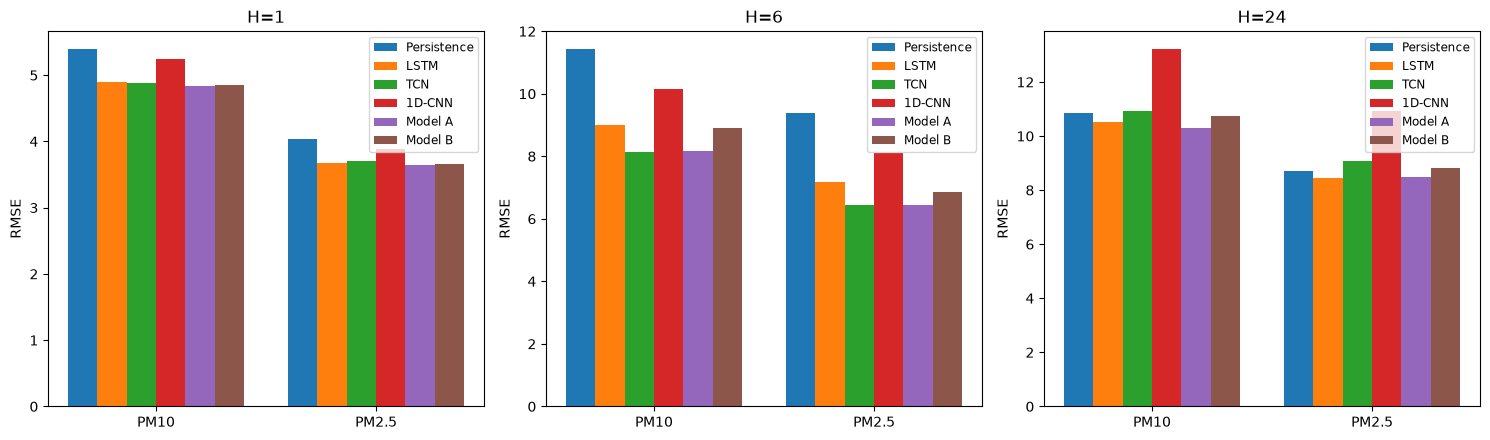

Saved RMSE comparison chart: e:\coding\DL2project\ebamtn_results\model_a_b_rmse_by_horizon.png


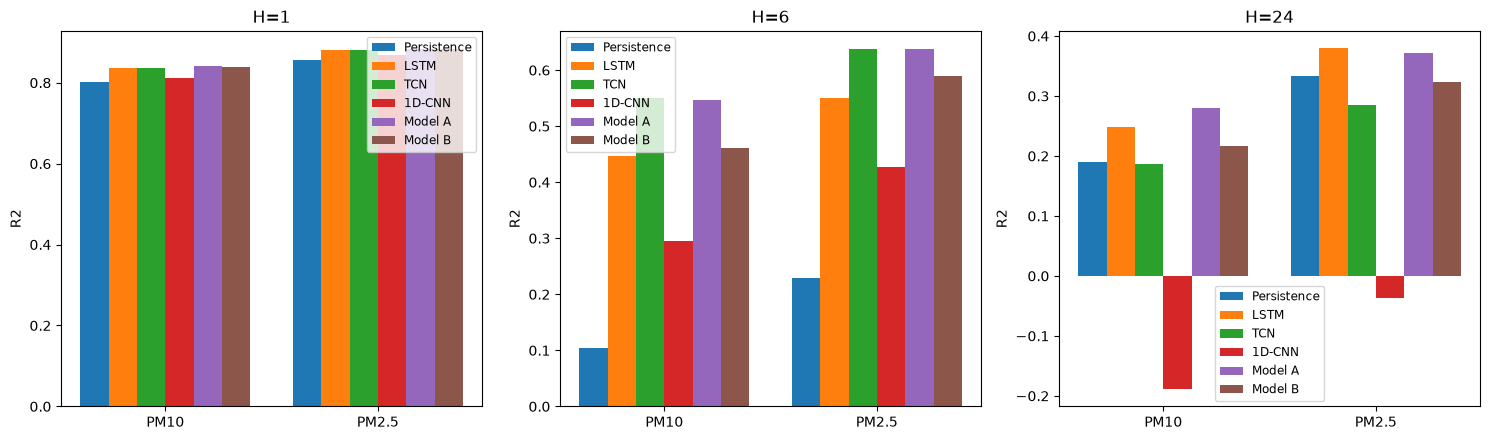

Saved R2 comparison chart: e:\coding\DL2project\ebamtn_results\model_a_b_r2_by_horizon.png


In [14]:
for metric_name, output_name in [
    ("RMSE", "model_a_b_rmse_by_horizon.png"),
    ("R2", "model_a_b_r2_by_horizon.png"),
]:
    figure, axes = plt.subplots(1, len(HORIZONS), figsize=(5 * len(HORIZONS), 4.5), squeeze=False)
    axes = axes.ravel()
    for axis, horizon in zip(axes, HORIZONS):
        horizon_rows = comparison_table.loc[comparison_table["horizon"].eq(horizon)]
        targets = [target for target in TARGETS if target in set(horizon_rows["target"])]
        x_positions = np.arange(len(targets))
        plot_models = [
            model_name for model_name in available_models
            if f"{model_name}_{metric_name}" in horizon_rows.columns
            and horizon_rows[f"{model_name}_{metric_name}"].notna().any()
        ]
        if not plot_models or not targets:
            axis.set_visible(False)
            continue
        bar_width = 0.8 / len(plot_models)
        for model_index, model_name in enumerate(plot_models):
            values = []
            for target in targets:
                matching = horizon_rows.loc[horizon_rows["target"].eq(target)]
                values.append(
                    matching[f"{model_name}_{metric_name}"].iloc[0]
                    if not matching.empty else np.nan
                )
            offsets = x_positions + (model_index - (len(plot_models) - 1) / 2) * bar_width
            axis.bar(offsets, values, width=bar_width, label=model_name)
        axis.set_xticks(x_positions)
        axis.set_xticklabels(targets)
        axis.set_title(f"H={horizon}")
        axis.set_ylabel(metric_name)
        axis.legend(fontsize="small")
    figure.tight_layout()
    figure_path = RESULTS_DIR / output_name
    figure.savefig(figure_path, dpi=150)
    plt.show()
    plt.close(figure)
    print(f"Saved {metric_name} comparison chart: {figure_path}")


## 14. Training time and parameter counts

Reads existing baseline and Model A summaries and any saved Model B summary; missing files are reported without retraining.

In [15]:
training_parameter_rows = []
baseline_training_path = PROJECT_DIR / "tcn_cnn_results" / "training_time_parameter_counts.csv"
if baseline_training_path.is_file():
    baseline_table = pd.read_csv(baseline_training_path)
    baseline_name_map = {
        "LSTM (reference)": "LSTM",
        "LSTM": "LSTM",
        "TCN": "TCN",
        "1D-CNN": "1D-CNN",
    }
    for _, row in baseline_table.iterrows():
        model_name = baseline_name_map.get(str(row.get("model", "")))
        if model_name:
            training_parameter_rows.append({
                "model": model_name,
                "horizon": "all",
                "trainable_parameters": row.get("trainable_parameters", np.nan),
                "training_time_seconds": row.get("training_time_seconds", np.nan),
            })
else:
    print(f"Baseline training-time table not found: {baseline_training_path}")

for prefix, model_name in [("model_a", "Model A"), ("model_b", "Model B")]:
    summary_file = RESULTS_DIR / f"{prefix}_training_summary.csv"
    if not summary_file.is_file():
        print(f"Training summary not found for {model_name}: {summary_file}")
        continue
    summary_data = pd.read_csv(summary_file)
    for _, row in summary_data.iterrows():
        training_parameter_rows.append({
            "model": model_name,
            "horizon": row.get("horizon", np.nan),
            "trainable_parameters": row.get("trainable_parameters", np.nan),
            "training_time_seconds": row.get("training_time_seconds", np.nan),
        })

if not any(row["model"] == "Model B" for row in training_parameter_rows):
    training_parameter_rows.append({
        "model": "Model B",
        "horizon": "NOT AVAILABLE / NOT RUN",
        "trainable_parameters": MODEL_B_PARAMETER_COUNT,
        "training_time_seconds": np.nan,
    })
training_parameter_table = pd.DataFrame(training_parameter_rows)
training_parameter_path = RESULTS_DIR / "model_b_training_time_parameter_counts.csv"
training_parameter_table.to_csv(training_parameter_path, index=False)
display(training_parameter_table)
print(f"Saved training-time/parameter table: {training_parameter_path}")


,model,horizon,trainable_parameters,training_time_seconds
0,TCN,all,115778,6223.028324
1,1D-CNN,all,20194,3578.313163
2,LSTM,all,53378,NaN
3,Model A,1,118661,59797.466140
4,Model A,6,118661,3094.341643
5,Model A,24,118661,40312.670978
6,Model B,1,250754,10077.218429
7,Model B,6,250754,4107.061321
8,Model B,24,250754,4145.678934


Saved training-time/parameter table: e:\coding\DL2project\ebamtn_results\model_b_training_time_parameter_counts.csv


## 15. My conclusions

- H=1: [Write your conclusion here.]
- H=6: [Write your conclusion here.]
- H=24: [Write your conclusion here.]
- Comparison with persistence and Model A: [Write your conclusion here.]
- Limitations and next steps: [Write your conclusion here.]